In [103]:
# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [104]:
# Step 2 — Upload and load your dataset

In [105]:
# Load your dataset
df = pd.read_csv(
    r"C:\Users\talla\Downloads\ecommerce_dirty_dataset.csv")


In [106]:
# Display first five rows
df.head()

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
0,1,13-04-2022,14-04-2022,1992,Consumer,East,Odisha,Clothing,Kids,Kids Product 3,14492.0,5,0.20,1621.85,328.0,Cash on Delivery
1,2,12-03-2023,13-03-2023,4347,Corporate,East,Bihar,Electronics,Laptop,Laptop Product 100,47633.0,1,0.05,5774.48,340.0,Cash on Delivery
2,3,28-09-2022,04-10-2022,2195,Corporate,West,Maharashtra,Clothing,Women,Women Product 1,4058.1,1,0.10,521.04,348.0,Credit Card
3,4,17-04-2022,21-04-2022,3425,Consumer,South,Tamil Nadu,Electronics,Laptop,Laptop Product 139,61980.0,4,0.00,6695.36,62.0,Cash on Delivery
4,5,13-03-2022,20-03-2022,2967,NaN,North,Haryana,Clothing,Women,Women Product 50,6807.0,3,0.00,2653.83,94.0,Debit Card


In [107]:
# Step 4 — Check the number of rows and columns

In [108]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (100500, 16)


In [109]:
# Step 5 — Display all column names

In [110]:
print("Column names:")
print(df.columns)

Column names:
Index(['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID',
       'Customer_Segment', 'Region', 'State', 'Product_Category',
       'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Shipping_Cost', 'Payment_Mode'],
      dtype='str')


In [111]:
# Step 6 — Check data types

In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100500 entries, 0 to 100499
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Order_ID          100500 non-null  int64  
 1   Order_Date        100500 non-null  str    
 2   Ship_Date         100500 non-null  str    
 3   Customer_ID       100500 non-null  int64  
 4   Customer_Segment  97481 non-null   str    
 5   Region            100500 non-null  str    
 6   State             100500 non-null  str    
 7   Product_Category  100500 non-null  str    
 8   Sub_Category      100500 non-null  str    
 9   Product_Name      100500 non-null  str    
 10  Sales             100500 non-null  float64
 11  Quantity          100500 non-null  int64  
 12  Discount          100500 non-null  float64
 13  Profit            97481 non-null   float64
 14  Shipping_Cost     97494 non-null   float64
 15  Payment_Mode      100500 non-null  str    
dtypes: float64(4), int64(3), str(9)

In [113]:
# Step 7 — Check missing values

In [114]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Order_ID               0
Order_Date             0
Ship_Date              0
Customer_ID            0
Customer_Segment    3019
Region                 0
State                  0
Product_Category       0
Sub_Category           0
Product_Name           0
Sales                  0
Quantity               0
Discount               0
Profit              3019
Shipping_Cost       3006
Payment_Mode           0
dtype: int64


# Phase 1- Data Cleaning

In [115]:
# Make a copy of the original data

In [116]:
df_clean = df.copy()

In [117]:
df = pd.read_csv(r"C:\Users\talla\OneDrive\Documents\Desktop\Ecommerce_Sales_Project\ecommerce_dirty_dataset.csv")

df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original shape: (100019, 16)
Working copy shape: (100019, 16)


In [118]:
# Step 8 — Check duplicate rows

In [119]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 1


In [120]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (100018, 16)
Remaining duplicates: 0


In [121]:
# Step 9 — Convert date columns into datetime format

In [122]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Ship_Date"] = pd.to_datetime(
    df["Ship_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print(df[["Order_Date", "Ship_Date"]].head())
print(df[["Order_Date", "Ship_Date"]].dtypes)

  Order_Date Ship_Date
0        NaT       NaT
1        NaT       NaT
2        NaT       NaT
3        NaT       NaT
4        NaT       NaT
Order_Date    datetime64[s]
Ship_Date     datetime64[s]
dtype: object


In [123]:
# Step 10 — Handle missing values

In [124]:
df["Customer_Segment"] = df["Customer_Segment"].fillna(
    df["Customer_Segment"].mode()[0]
)

In [125]:
df["Profit"] = df["Profit"].fillna(df["Profit"].median())

df["Shipping_Cost"] = df["Shipping_Cost"].fillna(
    df["Shipping_Cost"].median()
)

In [126]:
print(df.isnull().sum())

Order_ID                 0
Order_Date          100018
Ship_Date           100018
Customer_ID              0
Customer_Segment         0
Region                   0
State                    0
Product_Category         0
Sub_Category             0
Product_Name             0
Sales                    0
Quantity                 0
Discount                 0
Profit                   0
Shipping_Cost            0
Payment_Mode             0
dtype: int64


In [127]:
# Step 11 — Check invalid shipping dates

In [128]:
# Find rows where Ship_Date is earlier than Order_Date

invalid_dates = df[df["Ship_Date"] < df["Order_Date"]]

print("Invalid shipping date records:", len(invalid_dates))


Invalid shipping date records: 0


In [129]:
# Display the invalid records
invalid_dates.head()

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode


In [130]:
# Replace invalid shipping dates with NaT

df.loc[df["Ship_Date"] < df["Order_Date"], "Ship_Date"] = pd.NaT

print("Invalid shipping dates corrected.")

Invalid shipping dates corrected.


In [131]:
# Step 12 — Identify negative sales

In [132]:
# Find records with negative sales

negative_sales = df[df["Sales"] < 0]

print("Records with negative sales:", len(negative_sales))

negative_sales.head()

Records with negative sales: 150


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
470,471,NaT,NaT,4375,Corporate,East,Odisha,Electronics,Accessories,Accessories Product 54,-5000.0,5,0.15,75466.83,428.0,UPI
1706,1707,NaT,NaT,1749,Consumer,East,West Bengal,Furniture,Chair,Chair Product 160,-5000.0,2,0.10,8349.24,58.0,UPI
3627,3628,NaT,NaT,1171,Home Office,North,Haryana,Electronics,Laptop,Laptop Product 182,-5000.0,5,0.05,51986.61,207.0,Cash on Delivery
4186,4187,NaT,NaT,4931,Consumer,West,Maharashtra,Clothing,Women,Women Product 177,-5000.0,2,0.00,2105.71,443.0,UPI
6067,6068,NaT,NaT,2880,Consumer,North,Haryana,Clothing,Men,Men Product 184,-5000.0,3,0.00,2326.83,239.0,Debit Card


In [133]:
df = df[df["Sales"] >= 0].copy()

print("Shape after handling negative sales:", df.shape)

Shape after handling negative sales: (99868, 16)


In [134]:
# Step 13 — Check invalid discounts

In [135]:
print("Minimum discount:", df["Discount"].min())
print("Maximum discount:", df["Discount"].max())

print("Unique discount values:")
print(df["Discount"].dropna().unique()[:20])

Minimum discount: 0.0
Maximum discount: 0.9
Unique discount values:
[0.2  0.05 0.1  0.   0.3  0.5  0.15 0.9 ]


In [136]:
# Identify discounts above 80%
high_discount = df[df["Discount"] > 0.80]

print("Discounts above 80%:", len(high_discount))

high_discount.head()

Discounts above 80%: 200


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
516,517,NaT,NaT,1820,Corporate,East,West Bengal,Clothing,Kids,Kids Product 154,19679.25,5,0.9,6259.19,474.0,UPI
1126,1127,NaT,NaT,1548,Corporate,North,Delhi,Furniture,Table,Table Product 42,42547.50,5,0.9,6770.94,368.0,UPI
1494,1495,NaT,NaT,3962,Corporate,North,Punjab,Furniture,Sofa,Sofa Product 176,12301.55,1,0.9,4431.19,482.0,Credit Card
2123,2124,NaT,NaT,4468,Corporate,North,Haryana,Furniture,Sofa,Sofa Product 57,4675.00,1,0.9,1471.27,162.0,UPI
3329,3330,NaT,NaT,4787,Corporate,West,Maharashtra,Clothing,Men,Men Product 3,20372.75,5,0.9,6280.52,102.0,Cash on Delivery


In [137]:
# Step 14 — Identify unusually high shipping costs

In [138]:
# Calculate quartiles
Q1 = df["Shipping_Cost"].quantile(0.25)
Q3 = df["Shipping_Cost"].quantile(0.75)

In [139]:
# Calculate interquartile range
IQR = Q3 - Q1

In [140]:
# Calculate outlier boundaries
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


Lower limit: -162.5
Upper limit: 713.5


In [141]:
# Identify outliers
shipping_outliers = df[
    (df["Shipping_Cost"] < lower_limit) |
    (df["Shipping_Cost"] > upper_limit)
]

print("Shipping cost outliers:", len(shipping_outliers))

shipping_outliers.head()

Shipping cost outliers: 100


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
1426,1427,NaT,NaT,1623,Home Office,North,Punjab,Furniture,Sofa,Sofa Product 101,2813.00,1,0.00,912.15,10000.0,Debit Card
1499,1500,NaT,NaT,3506,Consumer,South,Telangana,Electronics,Laptop,Laptop Product 171,38187.80,1,0.30,9477.21,10000.0,Debit Card
1764,1765,NaT,NaT,3306,Corporate,South,Karnataka,Furniture,Table,Table Product 28,15566.40,4,0.10,4423.36,10000.0,UPI
2510,2511,NaT,NaT,1972,Consumer,West,Maharashtra,Electronics,Laptop,Laptop Product 154,139930.25,5,0.05,22472.26,10000.0,Cash on Delivery
2672,2673,NaT,NaT,4830,Consumer,East,Bihar,Clothing,Kids,Kids Product 134,8124.30,2,0.15,1113.57,10000.0,Cash on Delivery


In [142]:
# Step 15 — Identify profit outliers

In [143]:
Q1_profit = df["Profit"].quantile(0.25)
Q3_profit = df["Profit"].quantile(0.75)

IQR_profit = Q3_profit - Q1_profit

lower_profit = Q1_profit - 1.5 * IQR_profit
upper_profit = Q3_profit + 1.5 * IQR_profit

profit_outliers = df[
    (df["Profit"] < lower_profit) |
    (df["Profit"] > upper_profit)
]

print("Lower profit limit:", lower_profit)
print("Upper profit limit:", upper_profit)
print("Profit outliers:", len(profit_outliers))

profit_outliers.head()

Lower profit limit: -17993.594999999998
Upper profit limit: 34869.485
Profit outliers: 10156


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
15,16,NaT,NaT,2379,Home Office,East,Odisha,Electronics,Laptop,Laptop Product 110,258922.75,5,0.15,59186.74,231.0,Cash on Delivery
16,17,NaT,NaT,4077,Consumer,East,Odisha,Electronics,Laptop,Laptop Product 69,357322.50,5,0.10,97920.08,377.0,Cash on Delivery
24,25,NaT,NaT,1149,Corporate,West,Gujarat,Electronics,Accessories,Accessories Product 36,278719.20,4,0.10,73920.24,317.0,Debit Card
25,26,NaT,NaT,1412,Consumer,North,Haryana,Electronics,Laptop,Laptop Product 16,239243.25,5,0.05,93913.43,285.0,Cash on Delivery
29,30,NaT,NaT,4959,Corporate,East,Odisha,Electronics,Laptop,Laptop Product 37,65041.20,4,0.10,500000.00,442.0,Cash on Delivery


In [144]:
# Step 16 — Standardize text and product categories

In [145]:
# Remove unnecessary spaces from text columns

text_columns = df.select_dtypes(include=["object", "string"]).columns

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

In [146]:
# Standardize product category names

df["Product_Category"] = (
    df["Product_Category"]
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

print("Product categories after standardization:")
print(df["Product_Category"].value_counts(dropna=False))

Product categories after standardization:
Product_Category
Electronics    33451
Clothing       33381
Furniture      33036
Name: count, dtype: int64[pyarrow]


In [147]:
# Step 17 — Check the cleaned dataset

In [148]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

df.head()

Final dataset shape: (99868, 16)

Missing values:
Order_ID                0
Order_Date          99868
Ship_Date           99868
Customer_ID             0
Customer_Segment        0
Region                  0
State                   0
Product_Category        0
Sub_Category            0
Product_Name            0
Sales                   0
Quantity                0
Discount                0
Profit                  0
Shipping_Cost           0
Payment_Mode            0
dtype: int64

Duplicate rows:
6

Data types:
Order_ID                    int64
Order_Date          datetime64[s]
Ship_Date           datetime64[s]
Customer_ID                 int64
Customer_Segment           string
Region                     string
State                      string
Product_Category           string
Sub_Category               string
Product_Name               string
Sales                     float64
Quantity                    int64
Discount                  float64
Profit                    float64
Shipping_Cost

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
0,1,NaT,NaT,1992,Consumer,East,Odisha,Clothing,Kids,Kids Product 3,14492.0,5,0.20,1621.85,328.0,Cash on Delivery
1,2,NaT,NaT,4347,Corporate,East,Bihar,Electronics,Laptop,Laptop Product 100,47633.0,1,0.05,5774.48,340.0,Cash on Delivery
2,3,NaT,NaT,2195,Corporate,West,Maharashtra,Clothing,Women,Women Product 1,4058.1,1,0.10,521.04,348.0,Credit Card
3,4,NaT,NaT,3425,Consumer,South,Tamil Nadu,Electronics,Laptop,Laptop Product 139,61980.0,4,0.00,6695.36,62.0,Cash on Delivery
4,5,NaT,NaT,2967,Unknown,North,Haryana,Clothing,Women,Women Product 50,6807.0,3,0.00,2653.83,94.0,Debit Card


In [149]:
# Step 18 — Save the cleaned dataset

In [150]:
# Export the cleaned dataset to a CSV file

df.to_csv("ecommerce_cleaned_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [151]:
# Save the cleaned dataset to a CSV file
df_clean.to_csv("ecommerce_cleaned_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [152]:
import os

print("File location:", os.path.abspath("ecommerce_cleaned_dataset.csv"))

File location: C:\Users\talla\Pavithra(python)\ecommerce_cleaned_dataset.csv


In [153]:
df_clean.to_csv(
    r"C:\Users\talla\OneDrive\Documents\Desktop\Ecommerce_Sales_Project\ecommerce_cleaned_dataset.csv",
    index=False
)

print("CSV file saved successfully!")

CSV file saved successfully!


# Phase 2: Exploratory Data Analysis (EDA)

In [154]:
# Import visualization libraries and check the cleaned data

In [155]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (99868, 16)


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
0,1,NaT,NaT,1992,Consumer,East,Odisha,Clothing,Kids,Kids Product 3,14492.0,5,0.20,1621.85,328.0,Cash on Delivery
1,2,NaT,NaT,4347,Corporate,East,Bihar,Electronics,Laptop,Laptop Product 100,47633.0,1,0.05,5774.48,340.0,Cash on Delivery
2,3,NaT,NaT,2195,Corporate,West,Maharashtra,Clothing,Women,Women Product 1,4058.1,1,0.10,521.04,348.0,Credit Card
3,4,NaT,NaT,3425,Consumer,South,Tamil Nadu,Electronics,Laptop,Laptop Product 139,61980.0,4,0.00,6695.36,62.0,Cash on Delivery
4,5,NaT,NaT,2967,Unknown,North,Haryana,Clothing,Women,Women Product 50,6807.0,3,0.00,2653.83,94.0,Debit Card


In [156]:
# Step 1: Analyze numerical columns
numeric_cols = [
    "Sales", "Profit", "Discount",
    "Quantity", "Shipping_Cost"
]

display(df_clean[numeric_cols].describe().T)

print("Skewness:")
display(df_clean[numeric_cols].skew())

,count,mean,std,min,25%,50%,75%,max
Sales,100019.0,51350.807173,68914.410905,-5000.00,7828.400,21259.20,63423.775,399965.0
Profit,97019.0,13115.547546,21747.779245,36.04,1761.695,5101.15,15576.080,500000.0
Discount,100019.0,0.120223,0.113526,0.00,0.050,0.10,0.200,0.9
Quantity,100019.0,2.997860,1.414855,1.00,2.000,3.00,4.000,5.0
Shipping_Cost,97021.0,285.430597,337.979471,50.00,163.000,276.00,388.000,10000.0


Skewness:


Sales             2.125032
Profit            7.439419
Discount          1.834151
Quantity         -0.000900
Shipping_Cost    24.462957
dtype: float64

In [157]:
# Step 2: Analyze sales by region, category and segment
# Sales by region
region_sales = df_clean.groupby("Region")["Sales"].sum()
display(region_sales.sort_values(ascending=False))

Region
North    1.312021e+09
West     1.285160e+09
East     1.280509e+09
South    1.258366e+09
Name: Sales, dtype: float64

In [158]:
# Sales by product category
category_sales = df_clean.groupby("Product_Category")["Sales"].sum()
display(category_sales.sort_values(ascending=False))

Product_Category
Electronics    3.932271e+09
Furniture      9.618333e+08
Clothing       2.419525e+08
Name: Sales, dtype: float64

In [159]:
# Sales by customer segment
segment_sales = df_clean.groupby("Customer_Segment")["Sales"].sum()
display(segment_sales.sort_values(ascending=False))

Customer_Segment
Corporate      1.673644e+09
Consumer       1.667618e+09
Home Office    1.641154e+09
Unknown        1.536392e+08
Name: Sales, dtype: float64

In [160]:
# Top 10 products
top_products = (
    df_clean.groupby("Product_Name")["Sales"]
    .sum()
    .nlargest(10)
)

display(top_products)

Product_Name
Mobile Product 3           10236847.95
Mobile Product 175         10198539.80
Laptop Product 113          9651849.50
Mobile Product 50           9518366.45
Accessories Product 22      9474879.15
Mobile Product 63           9407490.65
Mobile Product 128          9347845.40
Laptop Product 31           9239452.35
Mobile Product 5            9224325.00
Accessories Product 155     9189764.30
Name: Sales, dtype: float64

In [161]:
# Step 3: Analyze the relationship between discount and profit
discount_profit = df_clean.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Number_of_Records=("Order_ID", "count")
)

display(discount_profit)

,Average_Profit,Total_Profit,Number_of_Records
Discount,,,
0.00,14928.472277,2.875074e+08,19857
0.05,13912.999734,2.716652e+08,20156
0.10,13366.998451,2.581034e+08,19917
0.15,12730.910766,1.834779e+08,14828
0.20,11987.466207,1.753287e+08,15064
0.30,10594.214335,7.136263e+07,6952
0.50,7732.308710,2.284124e+07,3045
0.90,11019.388071,2.170819e+06,200


In [162]:
correlation = df_clean[
    ["Discount", "Profit"]
].corr()

display(correlation)

,Discount,Profit
Discount,1.000000,-0.067944
Profit,-0.067944,1.000000


In [163]:
# Step 5: Analyze customers
customer_sales = (
    df_clean.groupby("Customer_ID")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

top_20_count = int(np.ceil(len(customer_sales) * 0.20))

top_20_revenue = customer_sales.head(top_20_count).sum()
total_revenue = customer_sales.sum()

contribution = top_20_revenue / total_revenue * 100

print("Top 20% customers' revenue contribution:", contribution)

Top 20% customers' revenue contribution: 29.846721593503716


In [164]:
# Charts

In [165]:
# Convert columns to appropriate data types
for col in ["Sales", "Profit", "Discount",
            "Quantity", "Shipping_Cost"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["Order_Date", "Ship_Date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Set chart style
sns.set_theme(style="whitegrid")

In [223]:
from pathlib import Path

chart_folder = Path("charts")
chart_folder.mkdir(exist_ok=True)

print("Charts folder is ready:", chart_folder.resolve())

Charts folder is ready: C:\Users\talla\Pavithra(python)\charts


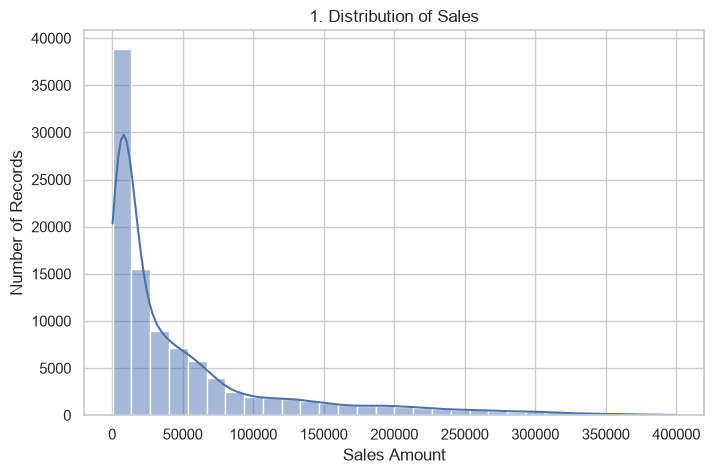

In [224]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Sales", bins=30, kde=True)

plt.title("1. Distribution of Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Records")
plt.savefig(
    chart_folder / "01_sales_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

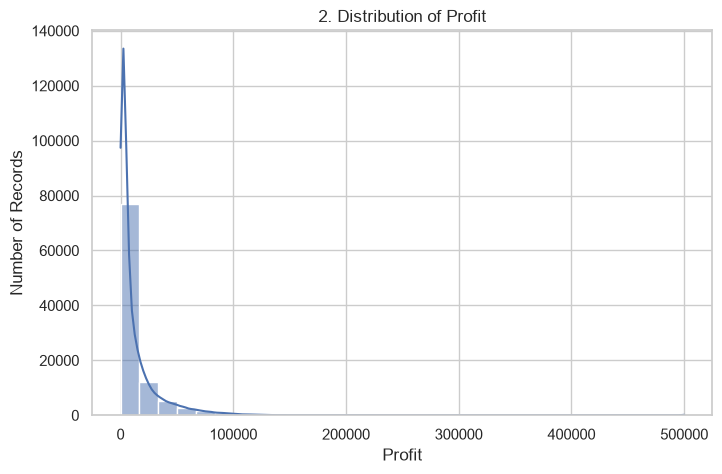

In [167]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Profit", bins=30, kde=True)

plt.title("2. Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Number of Records")

plt.show()

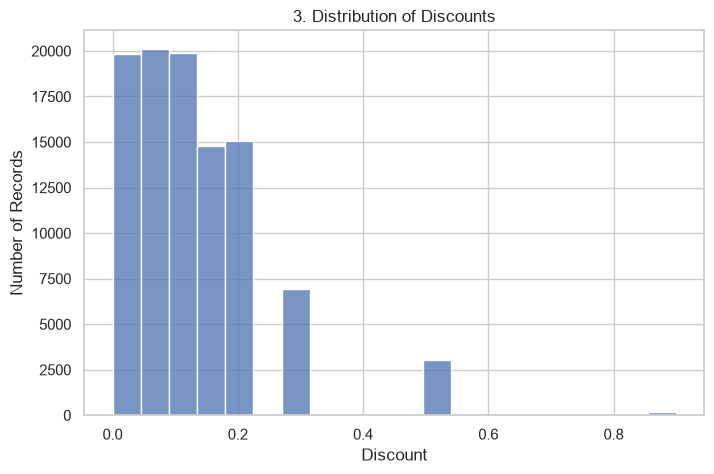

In [168]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Discount", bins=20)

plt.title("3. Distribution of Discounts")
plt.xlabel("Discount")
plt.ylabel("Number of Records")

plt.show()

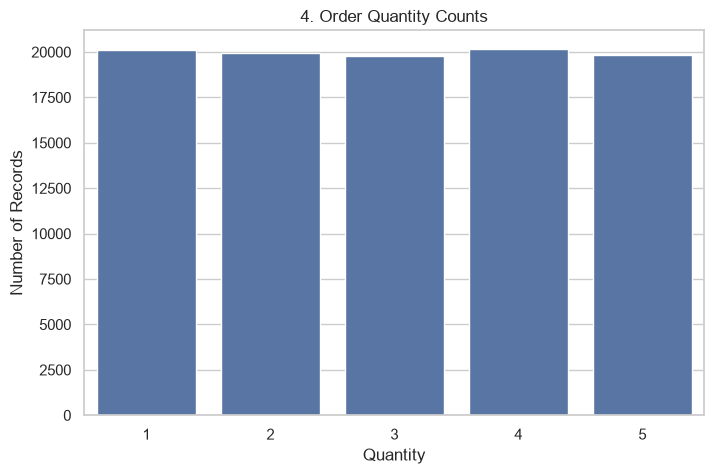

In [169]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Quantity")

plt.title("4. Order Quantity Counts")
plt.xlabel("Quantity")
plt.ylabel("Number of Records")

plt.show()

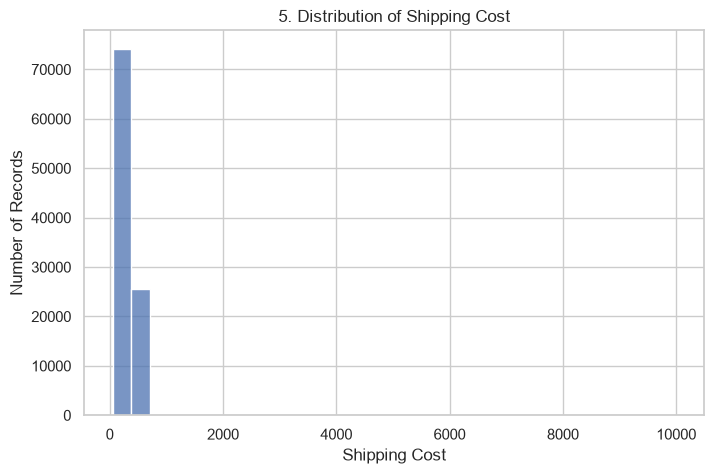

In [170]:
# Chart 5: Shipping-cost distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Shipping_Cost",
    bins=30
)

plt.title("5. Distribution of Shipping Cost")
plt.xlabel("Shipping Cost")
plt.ylabel("Number of Records")

plt.show()

# Create Charts 6–10 — Sales performance

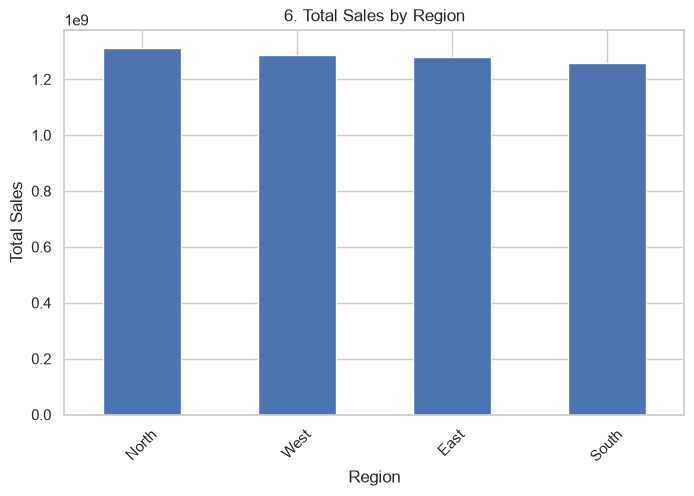

Region
North    1.311934e+09
West     1.285340e+09
East     1.280684e+09
South    1.258576e+09
Name: Sales, dtype: float64

In [171]:
# Chart 6: Sales by region
sales_region = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

sales_region.plot(kind="bar", figsize=(8, 5))

plt.title("6. Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

display(sales_region)

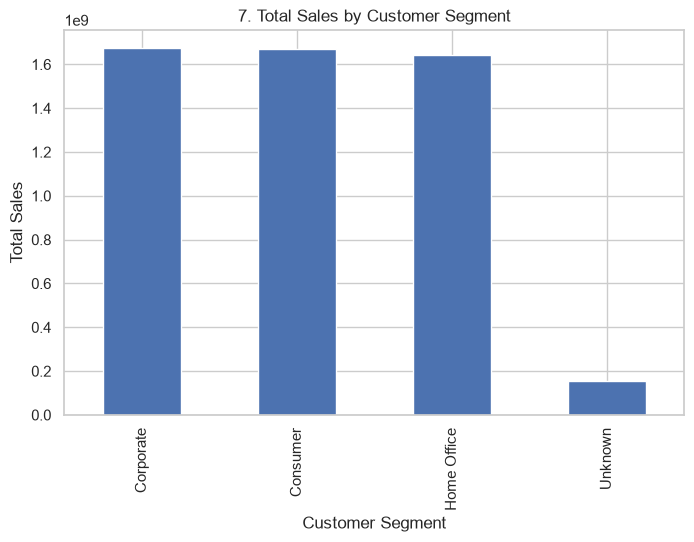

Customer_Segment
Corporate      1.673627e+09
Consumer       1.667883e+09
Home Office    1.641374e+09
Unknown        1.536492e+08
Name: Sales, dtype: float64

In [172]:
segment_sales = (
    df.groupby("Customer_Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

segment_sales.plot(kind="bar", figsize=(8, 5))

plt.title("7. Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.show()

display(segment_sales)

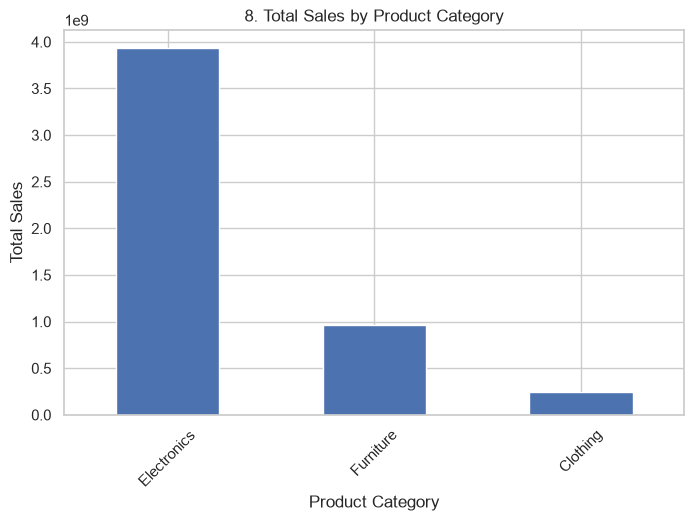

Product_Category
Electronics    3.932218e+09
Furniture      9.620633e+08
Clothing       2.422525e+08
Name: Sales, dtype: float64

In [173]:
# Chart 8: Sales by product category
category_sales = (
    df.groupby("Product_Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("8. Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

display(category_sales)

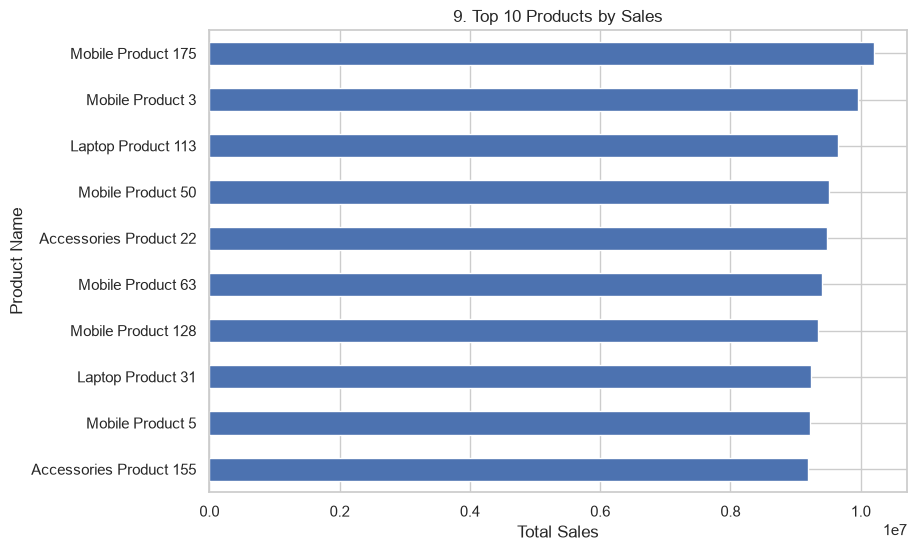

Product_Name
Mobile Product 175         10198539.80
Mobile Product 3            9964554.70
Laptop Product 113          9651849.50
Mobile Product 50           9518366.45
Accessories Product 22      9474879.15
Mobile Product 63           9407490.65
Mobile Product 128          9347845.40
Laptop Product 31           9239452.35
Mobile Product 5            9224325.00
Accessories Product 155     9189764.30
Name: Sales, dtype: float64

In [174]:
# Chart 9: Top 10 products by sales
top_products = (
    df.groupby("Product_Name")["Sales"]
    .sum()
    .nlargest(10)
    .sort_values()
)

top_products.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("9. Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")

plt.show()

display(top_products.sort_values(ascending=False))

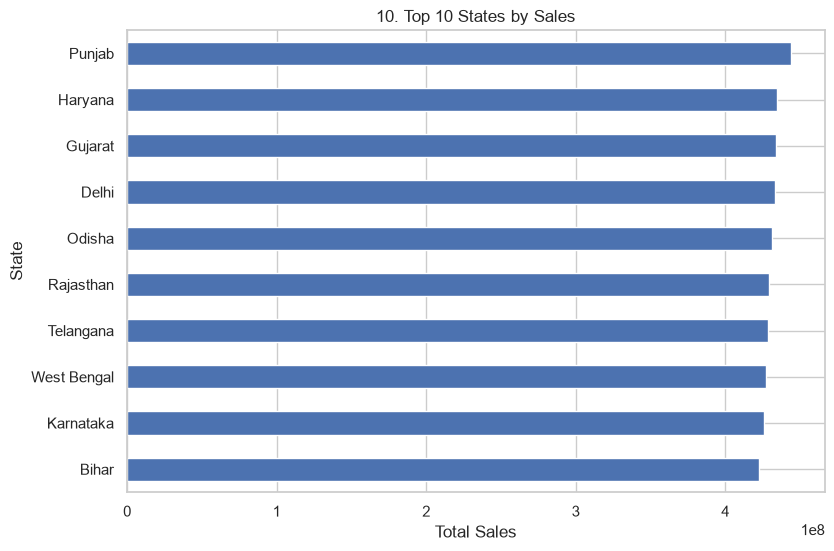

State
Punjab         4.442132e+08
Haryana        4.344080e+08
Gujarat        4.341091e+08
Delhi          4.333128e+08
Odisha         4.311395e+08
Rajasthan      4.293731e+08
Telangana      4.287108e+08
West Bengal    4.270656e+08
Karnataka      4.261801e+08
Bihar          4.224786e+08
Name: Sales, dtype: float64

In [175]:
# Chart 10: Top 10 states by sales
top_states = (
    df.groupby("State")["Sales"]
    .sum()
    .nlargest(10)
    .sort_values()
)

top_states.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("10. Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")

plt.show()

display(top_states.sort_values(ascending=False))

# Create Charts 11–15 — Profitability analysis

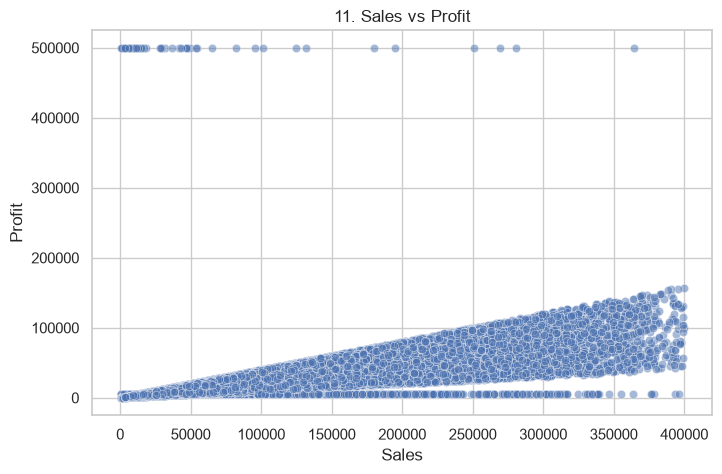

In [176]:
# Chart 11: Sales vs Profit
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    alpha=0.5
)

plt.title("11. Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

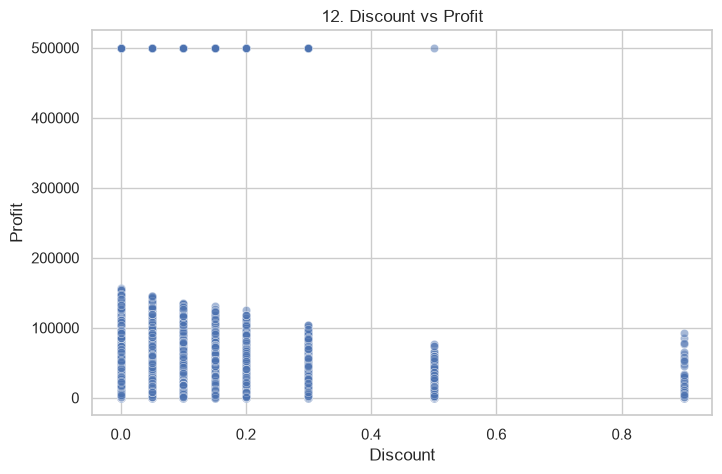

In [177]:
# Chart 12: Discount vs Profit
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.5
)

plt.title("12. Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

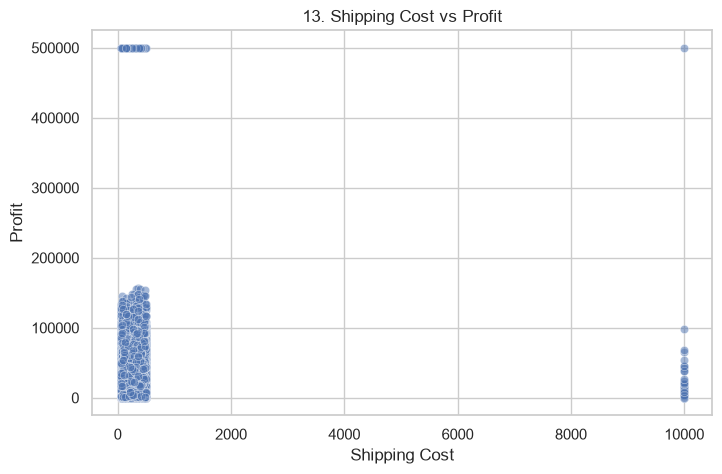

In [178]:
# Chart 13: Shipping cost vs Profit
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Shipping_Cost",
    y="Profit",
    alpha=0.5
)

plt.title("13. Shipping Cost vs Profit")
plt.xlabel("Shipping Cost")
plt.ylabel("Profit")

plt.show()

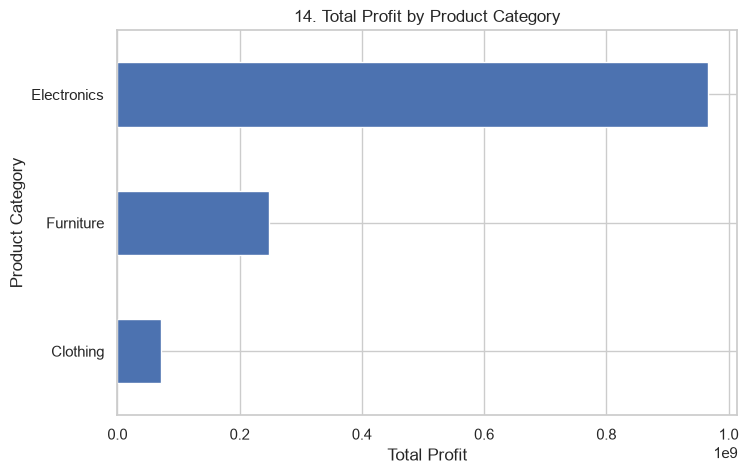

Product_Category
Electronics    9.661884e+08
Furniture      2.482410e+08
Clothing       7.151729e+07
Name: Profit, dtype: float64

In [179]:
# Chart 14: Profit by product category
profit_category = (
    df.groupby("Product_Category")["Profit"]
    .sum()
    .sort_values()
)

profit_category.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("14. Total Profit by Product Category")
plt.xlabel("Total Profit")
plt.ylabel("Product Category")

plt.show()

display(profit_category.sort_values(ascending=False))

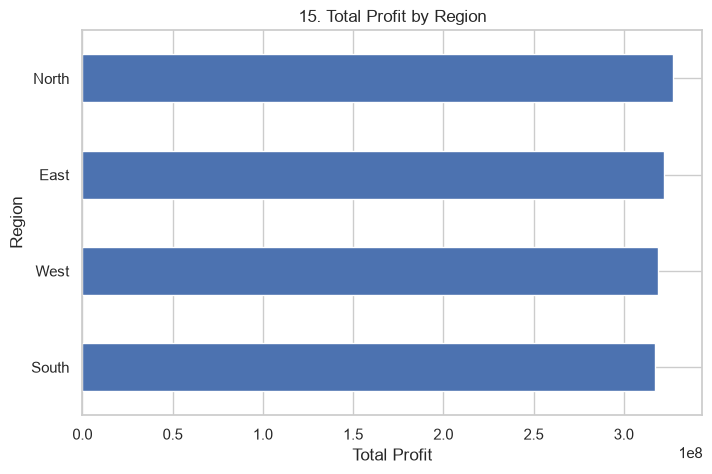

Region
North    3.272071e+08
East     3.224222e+08
West     3.187677e+08
South    3.175496e+08
Name: Profit, dtype: float64

In [180]:
# Chart 15: Profit by region
profit_region = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values()
)

profit_region.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("15. Total Profit by Region")
plt.xlabel("Total Profit")
plt.ylabel("Region")

plt.show()

display(profit_region.sort_values(ascending=False))

# Create Charts 16–20 — Trends and relationships

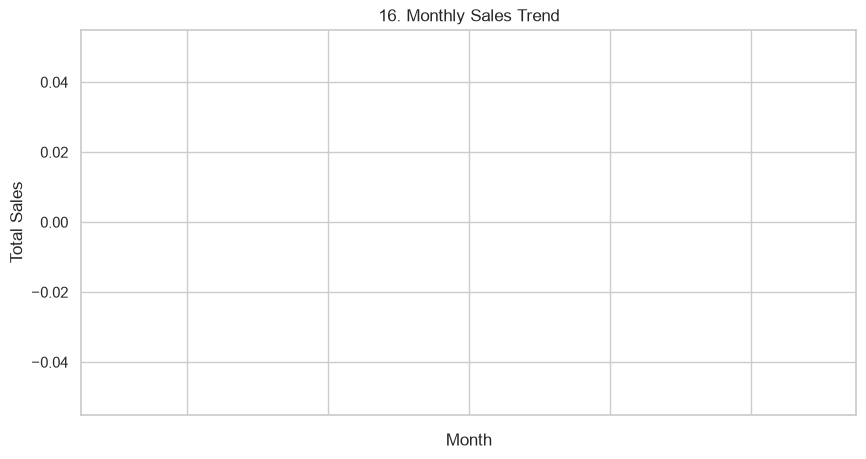

Series([], Name: Sales, dtype: float64)

In [181]:
# Chart 16: Monthly sales trend
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

monthly_sales = (
    df.dropna(subset=["Order_Date"])
    .groupby(
        df.loc[df["Order_Date"].notna(), "Order_Date"]
        .dt.to_period("M")
    )["Sales"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("16. Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

display(monthly_sales)

In [219]:
quarterly_growth = quarterly_sales.pct_change() * 100

display(quarterly_growth)

Series([], Name: Sales, dtype: float64)

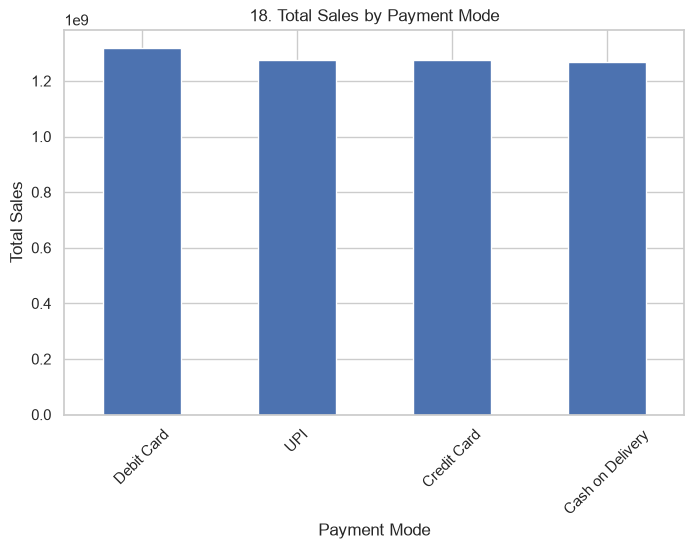

Payment_Mode
Debit Card          1.318682e+09
UPI                 1.275914e+09
Credit Card         1.274295e+09
Cash on Delivery    1.267644e+09
Name: Sales, dtype: float64

In [200]:
# Chart 18: Sales by payment mode
payment_sales = (
    df.groupby("Payment_Mode")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

payment_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("18. Total Sales by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

display(payment_sales)

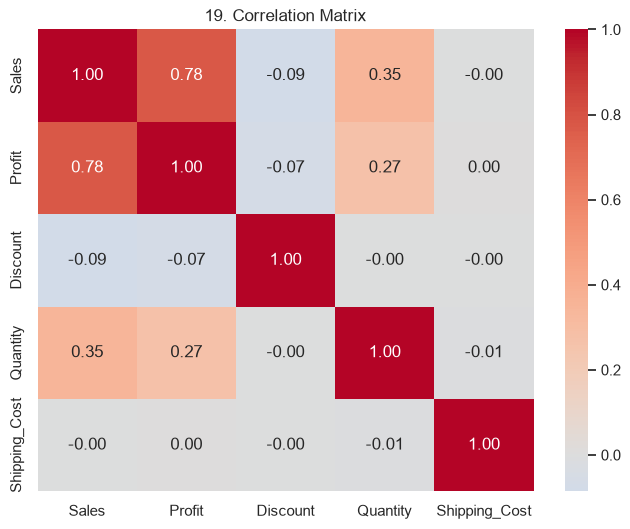

,Sales,Profit,Discount,Quantity,Shipping_Cost
Sales,1.000000,0.778124,-0.085866,0.349510,-0.004605
Profit,0.778124,1.000000,-0.066483,0.271394,0.003252
Discount,-0.085866,-0.066483,1.000000,-0.001358,-0.002712
Quantity,0.349510,0.271394,-0.001358,1.000000,-0.010096
Shipping_Cost,-0.004605,0.003252,-0.002712,-0.010096,1.000000


In [201]:
# Chart 19: Correlation matrix
numeric_cols = [
    "Sales",
    "Profit",
    "Discount",
    "Quantity",
    "Shipping_Cost"
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("19. Correlation Matrix")

plt.show()

display(correlation_matrix)

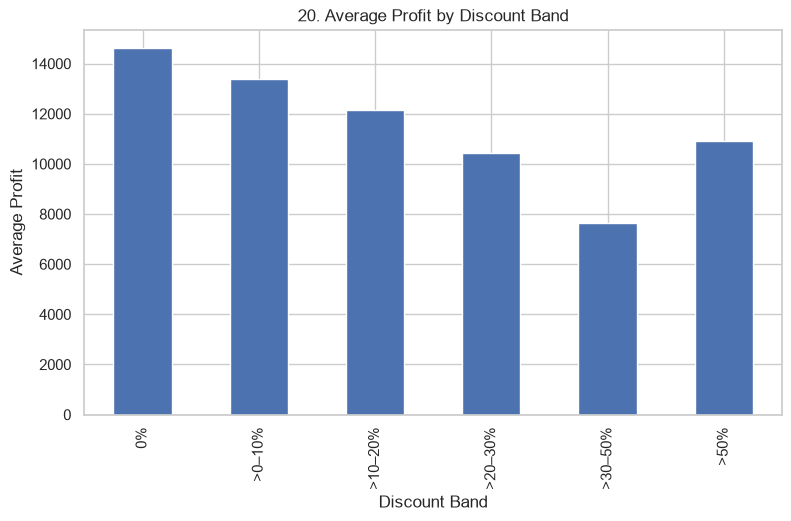

Discount_Band
0%         14625.757285
>0–10%     13378.915127
>10–20%    12154.825176
>20–30%    10425.963491
>30–50%     7658.106108
>50%       10930.613525
Name: Profit, dtype: float64

In [202]:
# Chart 20: Average profit by discount band
discount_data = df.dropna(
    subset=["Discount", "Profit"]
).copy()

discount_data["Discount_Band"] = pd.cut(
    discount_data["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.0],
    labels=[
        "0%",
        ">0–10%",
        ">10–20%",
        ">20–30%",
        ">30–50%",
        ">50%"
    ],
    include_lowest=True
)

avg_profit = discount_data.groupby(
    "Discount_Band",
    observed=False
)["Profit"].mean()

avg_profit.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("20. Average Profit by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Average Profit")

plt.show()

display(avg_profit)

In [183]:
from pathlib import Path

chart_folder = Path("charts")
chart_folder.mkdir(exist_ok=True)

print("Charts folder is ready:", chart_folder.resolve())

Charts folder is ready: C:\Users\talla\Pavithra(python)\charts


# Phase 3 — Business Insights

In [203]:
import pandas as pd
import numpy as np

# Confirm that the cleaned dataset is available
print("Dataset shape:", df_clean.shape)
print("Columns:", df_clean.columns.tolist())

# Ensure analysis columns are numeric
for col in ["Sales", "Profit", "Discount", "Shipping_Cost"]:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

Dataset shape: (100019, 16)
Columns: ['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID', 'Customer_Segment', 'Region', 'State', 'Product_Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping_Cost', 'Payment_Mode']


In [204]:
# Question 1 — Which region is most profitable?
# Calculate total sales and profit by region
region_analysis = (
    df_clean.groupby("Region", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Order_Count=("Order_ID", "nunique")
    )
    .sort_values("Total_Profit", ascending=False)
)

display(region_analysis.round(2))

# Identify the most profitable region
valid_regions = region_analysis.dropna(subset=["Total_Profit"])

if not valid_regions.empty:
    best_region = valid_regions["Total_Profit"].idxmax()
    best_profit = valid_regions.loc[best_region, "Total_Profit"]

    print("Most profitable region:", best_region)
    print("Total profit:", round(best_profit, 2))

,Total_Sales,Total_Profit,Average_Profit,Order_Count
Region,,,,
North,1.312021e+09,3.239582e+08,13239.00,25210
East,1.280509e+09,3.190515e+08,13189.40,24927
West,1.285160e+09,3.152923e+08,13032.92,24942
South,1.258366e+09,3.141553e+08,12999.35,24921


Most profitable region: North
Total profit: 323958221.61


In [205]:
# Question 2 — Which product category should be promoted?
category_analysis = (
    df_clean.groupby("Product_Category", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Record_Count=("Product_Category", "size")
    )
    .sort_values("Total_Profit", ascending=False)
)

display(category_analysis.round(2))

,Total_Sales,Total_Profit,Average_Profit,Record_Count
Product_Category,,,,
Electronics,3.932271e+09,9.624885e+08,29614.12,33496
Furniture,9.618333e+08,2.436007e+08,7586.68,33082
Clothing,2.419525e+08,6.636803e+07,2047.83,33441


In [206]:
valid_categories = category_analysis.dropna(
    subset=["Total_Profit"]
)

if not valid_categories.empty:
    best_category = valid_categories["Total_Profit"].idxmax()

    print("Highest-profit category:", best_category)
    print(
        "Total profit:",
        round(
            valid_categories.loc[best_category, "Total_Profit"],
            2
        )
    )

Highest-profit category: Electronics
Total profit: 962488538.56


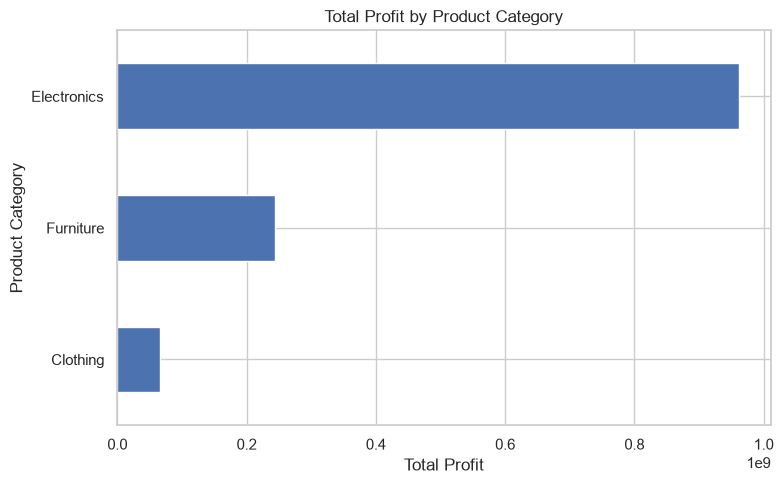

In [207]:
category_analysis["Total_Profit"].sort_values().plot(
    kind="barh", figsize=(8, 5)
)

plt.title("Total Profit by Product Category")
plt.xlabel("Total Profit")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [208]:
# Question 3 — Is the discount strategy hurting profitability?
# Check the discount scale
print(df_clean["Discount"].describe())

count    100019.000000
mean          0.120223
std           0.113526
min           0.000000
25%           0.050000
50%           0.100000
75%           0.200000
max           0.900000
Name: Discount, dtype: float64


In [209]:
# Group discounts into bands
discount_data = df_clean.dropna(
    subset=["Discount", "Profit"]
).copy()

discount_data["Discount_Band"] = pd.cut(
    discount_data["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.0],
    labels=[
        "0%",
        ">0–10%",
        ">10–20%",
        ">20–30%",
        ">30–50%",
        ">50%"
    ],
    include_lowest=True
)

discount_analysis = discount_data.groupby(
    "Discount_Band", observed=False
).agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Record_Count=("Profit", "size")
)

display(discount_analysis.round(2))

,Average_Profit,Total_Profit,Record_Count
Discount_Band,,,
0%,14928.47,2.875074e+08,19259
>0–10%,13641.52,5.297686e+08,38835
>10–20%,12356.45,3.588066e+08,29038
>20–30%,10594.21,7.136263e+07,6736
>30–50%,7732.31,2.284124e+07,2954
>50%,11019.39,2.170819e+06,197


In [210]:
discount_data["Discount_Band"] = pd.cut(
    discount_data["Discount"],
    bins=[-0.001, 0, 10, 20, 30, 50, 100],
    labels=[
        "0%",
        ">0–10%",
        ">10–20%",
        ">20–30%",
        ">30–50%",
        ">50%"
    ],
    include_lowest=True
)

In [211]:
# Calculate the correlation
discount_profit_corr = df_clean[
    ["Discount", "Profit"]
].corr().loc["Discount", "Profit"]

print(
    "Discount-profit correlation:",
    round(discount_profit_corr, 3)
)

Discount-profit correlation: -0.068


In [212]:
# Question 4 — Which customer segment generates the most revenue?
segment_analysis = (
    df_clean.groupby("Customer_Segment", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Order_Count=("Order_ID", "nunique")
    )
)

segment_analysis["Average_Order_Value"] = (
    segment_analysis["Total_Sales"]
    / segment_analysis["Order_Count"].replace(0, np.nan)
)

segment_analysis = segment_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(segment_analysis.round(2))

,Total_Sales,Total_Profit,Order_Count,Average_Order_Value
Customer_Segment,,,,
Corporate,1.673644e+09,4.132705e+08,32136,52080.05
Consumer,1.667618e+09,4.145874e+08,32483,51338.19
Home Office,1.641154e+09,4.063433e+08,32381,50682.63
Unknown,1.536392e+08,3.825613e+07,3000,51213.08


In [213]:
valid_segments = segment_analysis.dropna(
    subset=["Total_Sales"]
)

if not valid_segments.empty:
    best_segment = valid_segments["Total_Sales"].idxmax()

    print("Highest-revenue segment:", best_segment)
    print(
        "Total sales:",
        round(
            valid_segments.loc[best_segment, "Total_Sales"],
            2
        )
    )

Highest-revenue segment: Corporate
Total sales: 1673644429.55


In [214]:
# Question 5 — Is shipping cost impacting profit margins?
# Calculate profit margin
shipping_data = df_clean.dropna(
    subset=["Sales", "Profit", "Shipping_Cost"]
).copy()

# Calculate margins only when sales are positive
shipping_data = shipping_data[
    shipping_data["Sales"] > 0
].copy()

shipping_data["Profit_Margin_Percent"] = (
    shipping_data["Profit"]
    / shipping_data["Sales"]
) * 100

display(
    shipping_data[
        ["Sales", "Profit", "Shipping_Cost",
         "Profit_Margin_Percent"]
    ].head()
)

,Sales,Profit,Shipping_Cost,Profit_Margin_Percent
0,14492.0,1621.85,328.0,11.191347
1,47633.0,5774.48,340.0,12.122856
2,4058.1,521.04,348.0,12.839506
3,61980.0,6695.36,62.0,10.802452
4,6807.0,2653.83,94.0,38.986778


In [215]:
# Calculate correlations
shipping_correlations = shipping_data[
    ["Shipping_Cost", "Profit", "Profit_Margin_Percent"]
].corr()

display(shipping_correlations.round(3))

,Shipping_Cost,Profit,Profit_Margin_Percent
Shipping_Cost,1.000,0.003,0.002
Profit,0.003,1.000,0.222
Profit_Margin_Percent,0.002,0.222,1.000


In [216]:
# Compare shipping-cost bands
shipping_data["Shipping_Band"] = pd.qcut(
    shipping_data["Shipping_Cost"],
    q=4,
    duplicates="drop"
)

shipping_analysis = shipping_data.groupby(
    "Shipping_Band", observed=True
).agg(
    Average_Shipping_Cost=("Shipping_Cost", "mean"),
    Average_Profit=("Profit", "mean"),
    Average_Profit_Margin=("Profit_Margin_Percent", "mean"),
    Record_Count=("Shipping_Cost", "size")
)

display(shipping_analysis.round(2))

,Average_Shipping_Cost,Average_Profit,Average_Profit_Margin,Record_Count
Shipping_Band,,,,
"(49.999, 163.0]",107.00,13123.50,31.31,23644
"(163.0, 276.0]",220.08,13096.23,28.81,23501
"(276.0, 388.0]",332.61,13096.12,26.35,23397
"(388.0, 10000.0]",483.88,13124.98,29.18,23414


In [217]:
# Question 6 — Give five actionable recommendations
print("1. Regional profitability")
display(region_analysis[["Total_Sales", "Total_Profit"]])

print("\n2. Category performance")
display(category_analysis[
    ["Total_Sales", "Total_Profit", "Average_Profit"]
])

print("\n3. Discount analysis")
print("Discount-profit correlation:", round(discount_profit_corr, 3))
display(discount_analysis)

print("\n4. Customer segments")
display(segment_analysis)

print("\n5. Shipping analysis")
display(shipping_analysis)

1. Regional profitability


,Total_Sales,Total_Profit
Region,,
North,1.312021e+09,3.239582e+08
East,1.280509e+09,3.190515e+08
West,1.285160e+09,3.152923e+08
South,1.258366e+09,3.141553e+08



2. Category performance


,Total_Sales,Total_Profit,Average_Profit
Product_Category,,,
Electronics,3.932271e+09,9.624885e+08,29614.120752
Furniture,9.618333e+08,2.436007e+08,7586.681071
Clothing,2.419525e+08,6.636803e+07,2047.827031



3. Discount analysis
Discount-profit correlation: -0.068


,Average_Profit,Total_Profit,Record_Count
Discount_Band,,,
0%,14928.472277,2.875074e+08,19259
>0–10%,13641.524550,5.297686e+08,38835
>10–20%,12356.449022,3.588066e+08,29038
>20–30%,10594.214335,7.136263e+07,6736
>30–50%,7732.308710,2.284124e+07,2954
>50%,11019.388071,2.170819e+06,197



4. Customer segments


,Total_Sales,Total_Profit,Order_Count,Average_Order_Value
Customer_Segment,,,,
Corporate,1.673644e+09,4.132705e+08,32136,52080.048219
Consumer,1.667618e+09,4.145874e+08,32483,51338.191385
Home Office,1.641154e+09,4.063433e+08,32381,50682.630380
Unknown,1.536392e+08,3.825613e+07,3000,51213.075983



5. Shipping analysis


,Average_Shipping_Cost,Average_Profit,Average_Profit_Margin,Record_Count
Shipping_Band,,,,
"(49.999, 163.0]",106.996320,13123.500802,31.311300,23644
"(163.0, 276.0]",220.081911,13096.231527,28.807272,23501
"(276.0, 388.0]",332.606146,13096.124932,26.351553,23397
"(388.0, 10000.0]",483.879815,13124.979408,29.183446,23414


In [218]:
print(df_clean.columns.tolist())

['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID', 'Customer_Segment', 'Region', 'State', 'Product_Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping_Cost', 'Payment_Mode']
